---
title: "Figures: The Brock-Mirman Stochastic Growth Model"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Open this notebook in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/dsge/BrockMirman/BrockMirman.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/dsge/BrockMirman/BrockMirman.ipynb) to run it without installing anything.

Draws the two figures in [The Brock-Mirman Stochastic Growth Model](#sec:BrockMirman). Run all the cells to redraw them into `figures/`; change capital's share to see how the responses change.

Both figures follow log output after a one-time unit shock to log productivity, using the chapter's log-linear dynamics: log capital next period is a constant plus log productivity plus capital's share times log capital now, and log output is log productivity plus capital's share times log capital. In the first figure the shock to productivity is permanent (log productivity is a random walk); in the second it lasts one period (white noise). The figures replace static images drawn for the chapter's handout.

In [ ]:
# Run anywhere: install the book's package (it brings numpy, scipy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    import importlib.util, sys
    if importlib.util.find_spec("pip"):
        %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io
    else:  # a Python without pip, as uv makes: install with uv, or say what to do
        !uv pip install -q --python {sys.executable} git+https://github.com/intertemporal-choice/intertemporal-choice.github.io || echo "Neither pip nor uv can install the book's package here: choose a kernel whose Python has pip, or the course's own environment."

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from intertemporal_choice import notation, style

style.use_book_style()

In [ ]:
alpha = 1 / 3                 # capital's share of output
periods = np.arange(-3, 9)    # the shock arrives in period 0, labeled t


def log_output_gap(log_productivity_gap):
    """Log output minus its steady state, period by period, given log productivity minus its
    steady state. Log capital's gap is last period's productivity gap plus alpha times last
    period's capital gap; log output's gap is the productivity gap plus alpha times the capital gap."""
    capital_gap = np.zeros_like(log_productivity_gap)
    for i in range(1, len(periods)):
        capital_gap[i] = log_productivity_gap[i - 1] + alpha * capital_gap[i - 1]
    return log_productivity_gap + alpha * capital_gap


def draw(gap, ticks):
    """Plot log output's path, labeling the steady state and the given levels above it."""
    fig, ax = plt.subplots(figsize=(8.5, 8.5 / 1.618))
    ax.plot(periods, gap, "o", color="C0")
    for level in ticks:
        ax.axhline(level, color="gray", linestyle="--", linewidth=0.6)
    ax.set_yticks(list(ticks), [notation.tex(r"$\lnat\TargetNrm{\Inc}" + label + "$") for label in ticks.values()])
    ax.set_xticks([0, 1, 2], ["$t$", "$t+1$", "$t+2$"])
    ax.set_xlabel("Time", loc="right")
    ax.set_ylabel(notation.tex(r"$\lnat\Inc$"), loc="top", rotation=0)
    return fig

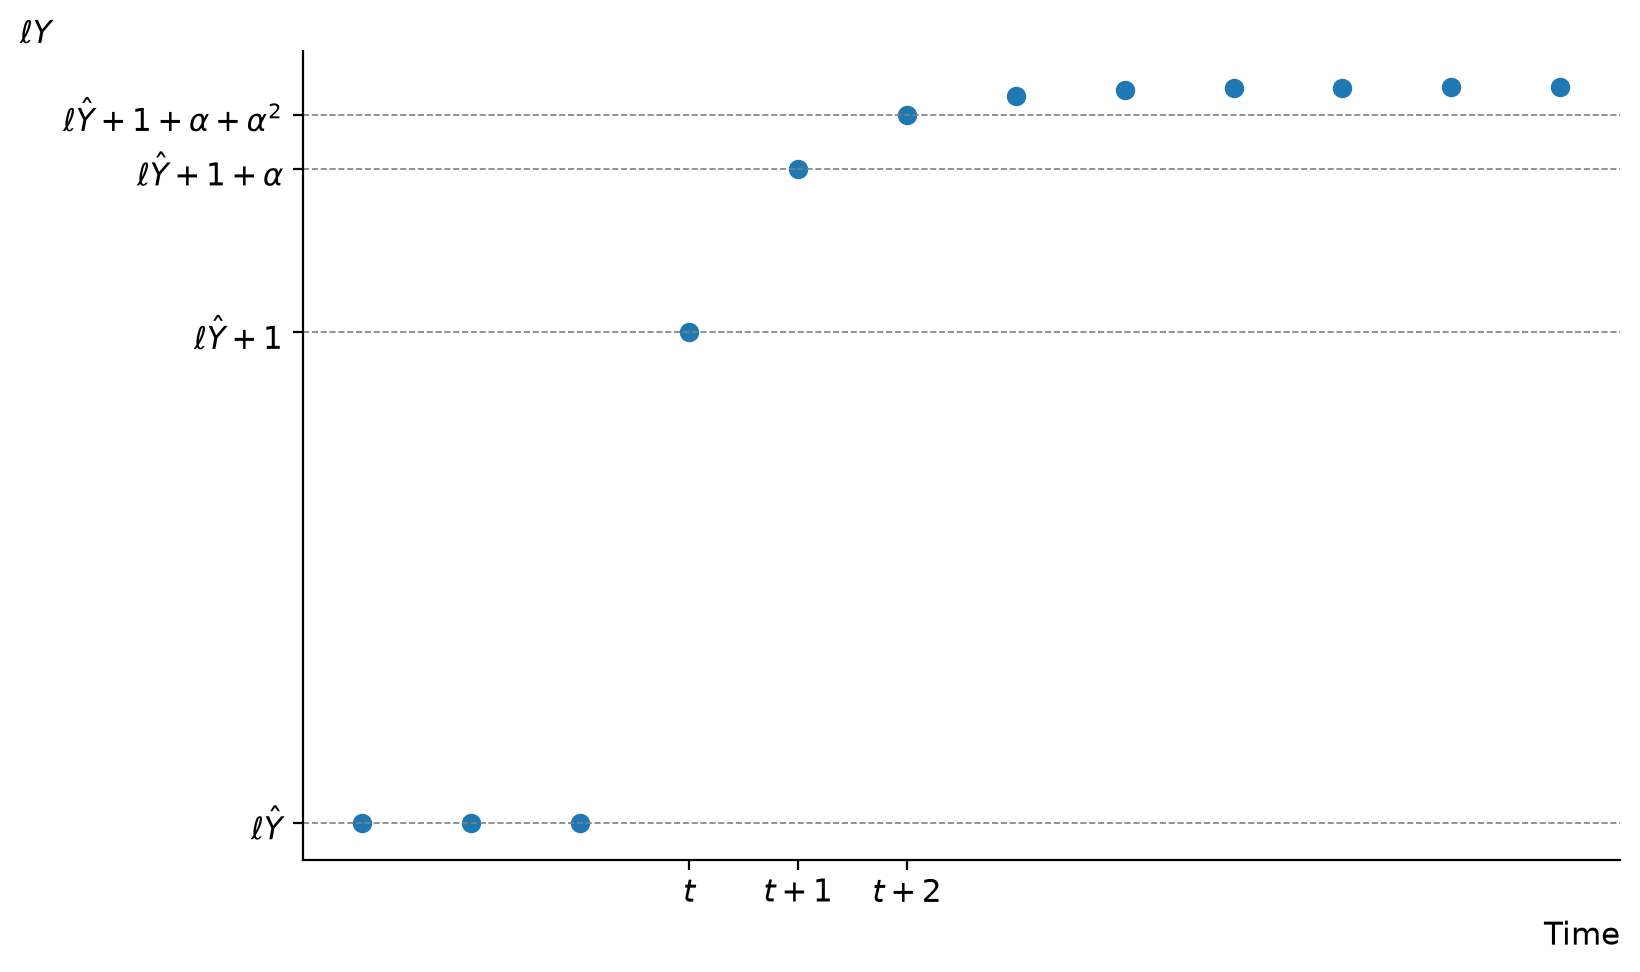

In [ ]:
shock = (periods >= 0).astype(float)    # log productivity rises by 1 for good
fig = draw(log_output_gap(shock), {0: "", 1: "+1", 1 + alpha: r"+1+\kapShare", 1 + alpha + alpha**2: r"+1+\kapShare+\kapShare^{2}"})
style.save(fig, "RandomWalkShock")

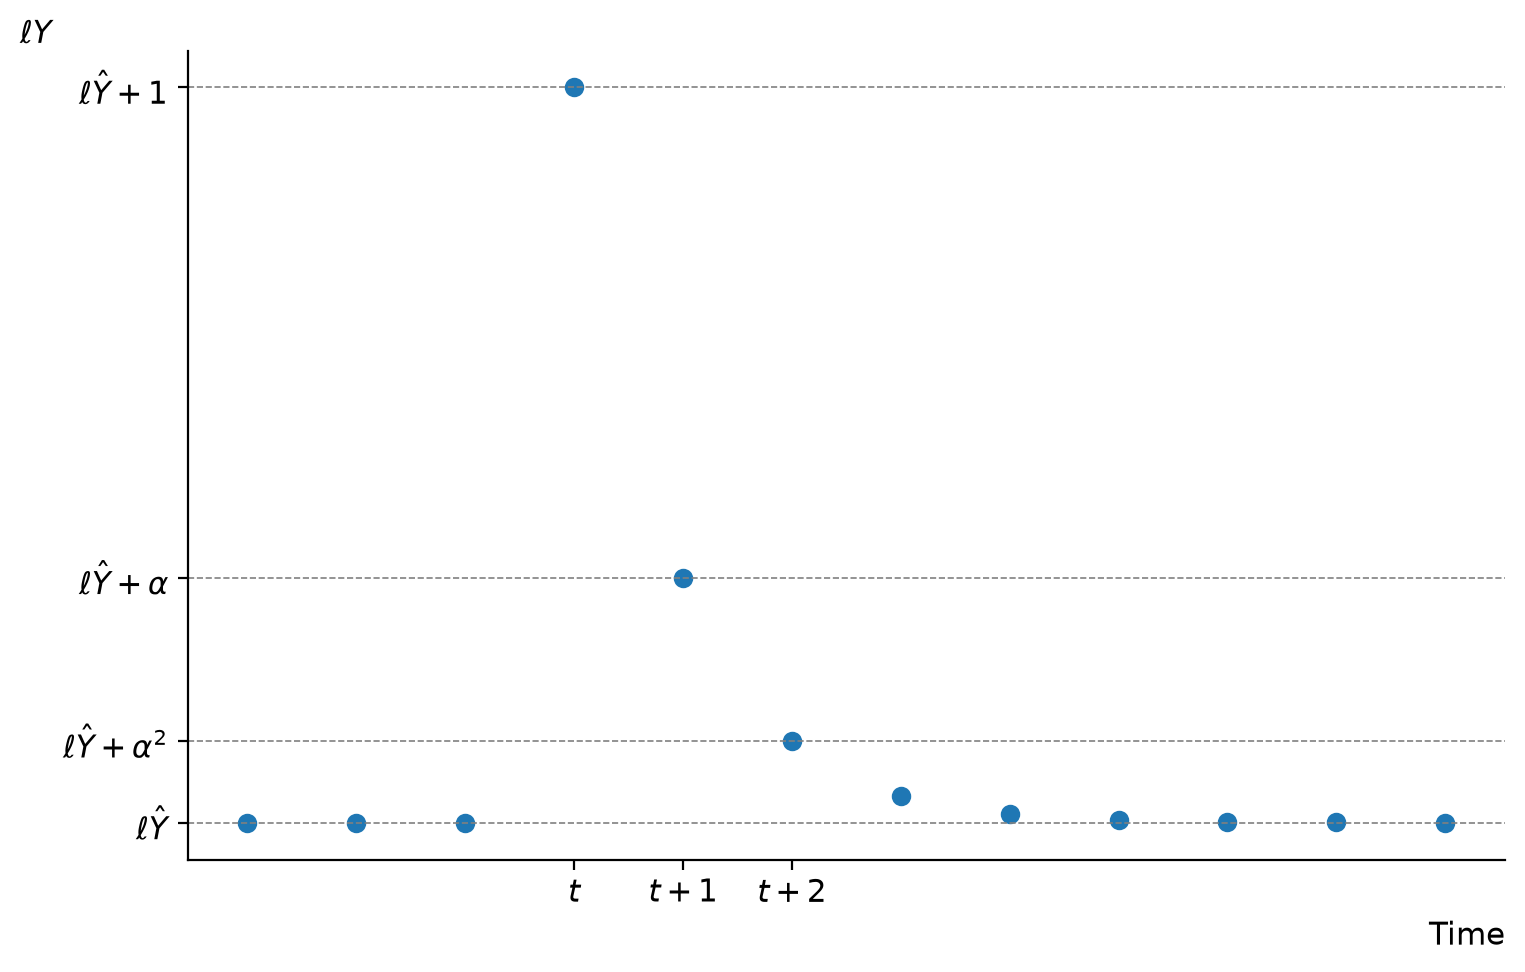

In [ ]:
shock = (periods == 0).astype(float)    # log productivity rises by 1 for one period only
fig = draw(log_output_gap(shock), {0: "", 1: "+1", alpha: r"+\kapShare", alpha**2: r"+\kapShare^{2}"})
style.save(fig, "WhiteNoiseShock")